# Taller: Grid Search — Optimización de Hiperparámetros


### Aprendizaje Supervisado — Validación Cruzada y `GridSearchCV`




**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 06-10-2026

> **Cómo usar este material:** este taller es una **guía de referencia en HTML**, no un notebook interactivo.
> Reproduce cada celda de código en tu propio Google Colab o Jupyter Notebook, en el mismo orden en que
> aparece: cada bloque usa los objetos creados en el anterior. Necesitas los archivos
> `credito_ecuador.csv` (Partes A y C) y `diabetes_ecuador.csv` (Parte B).


## Objetivos del taller



Al finalizar este taller el estudiante será capaz de:

1. Construir un modelo base (`StandardScaler` + `SVC`) dentro de un `Pipeline`.
2. Definir un `param_grid` con la notación `paso__parámetro` y ejecutar `GridSearchCV` con validación cruzada.
3. Interpretar `best_params_`, `best_score_` y `cv_results_`, y comparar el modelo optimizado con el modelo base en el conjunto de prueba.
4. Reentrenar el modelo final con el 100% de los datos, exportarlo con `joblib` y usarlo con datos nuevos.


## Datasets



**`credito_ecuador.csv`** — 600 solicitudes de crédito (dataset sintético, sin valores nulos). Partes A y C.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `edad` | Numérica | Edad del solicitante (22 a 64 años) |
| `ingresos_mensuales` | Numérica | Ingresos mensuales en USD |
| `deuda_total` | Numérica | Deuda acumulada en USD |
| `monto_solicitado` | Numérica | Monto del crédito solicitado en USD |
| `historial_crediticio` | Binaria (0/1) | 1 = historial positivo |
| `empleo_estable` | Binaria (0/1) | 1 = empleo estable |
| `aprobado` | Objetivo (y) | 1 = aprobado · 0 = rechazado |

**`diabetes_ecuador.csv`** — 600 pacientes (dataset sintético, sin valores nulos). Parte B.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `edad` | Numérica | Edad del paciente (años) |
| `imc` | Numérica | Índice de Masa Corporal |
| `glucosa` | Numérica | Glucosa en sangre (mg/dL) |
| `presion_diastolica` | Numérica | Presión diastólica (mmHg) |
| `actividad_fisica` | Binaria (0/1) | 1 = físicamente activo |
| `historial_familiar` | Binaria (0/1) | 1 = antecedentes familiares de diabetes |
| `diabetes` | Objetivo (y) | 1 = con diagnóstico · 0 = sin diagnóstico |


## Estructura del taller



| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración (crédito) |
| A2 | Guiado | X, y y división train/test |
| A3 | Guiado | Modelo base en un `Pipeline` |
| A4 | Guiado | `param_grid` y `GridSearchCV` |
| A5 | Guiado | Evaluación en prueba: base vs. optimizado |
| A6 | Guiado | Explorar `cv_results_` con un mapa de calor |
| B1 | Autónomo | Diabetes: datos y modelo base |
| B2 | Autónomo | Diabetes: `GridSearchCV` con `scoring='recall'` |
| B3 | Autónomo | Combinaciones repetidas: `param_grid` como lista de diccionarios |
| C | Guiado | Entrenamiento final (100%), exportación y uso con datos nuevos |



## Rúbrica de evaluación (10 puntos)



| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A6 y C (guiados) | Reproducidos completos y sin errores en tu notebook | 1.5 |
| B1 — código | Datos divididos con `stratify` y modelo base evaluado con Recall | 1.5 |
| B2 — código | `GridSearchCV` correcto (`modelo__`, `cv=5`, `scoring='recall'`) y evaluación en prueba | 2.0 |
| B2 — análisis | Tabla completa y respuestas justificadas | 2.0 |
| B3 — código | `param_grid` como lista de diccionarios ejecutado correctamente | 1.0 |
| B3 — análisis | Respuestas justificadas | 2.0 |


# Parte A — Laboratorio Guiado: Aprobación de Crédito


## Bloque A1 · Carga y exploración



**Librerías que usamos:** `pandas` (datos) y `matplotlib.pyplot` (gráficos).


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('credito_ecuador.csv')
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()


Filas: 600 | Columnas: 7


,edad,ingresos_mensuales,deuda_total,monto_solicitado,historial_crediticio,empleo_estable,aprobado
0,60,1289.64,2647.22,8200.97,0,1,0
1,50,1205.04,7601.88,9547.82,0,1,0
2,36,1239.07,3919.68,3312.36,1,0,1
3,64,890.80,1138.45,6412.84,0,0,0
4,29,1209.80,4256.21,10382.79,1,1,1


aprobado
0    313
1    287
Name: count, dtype: int64


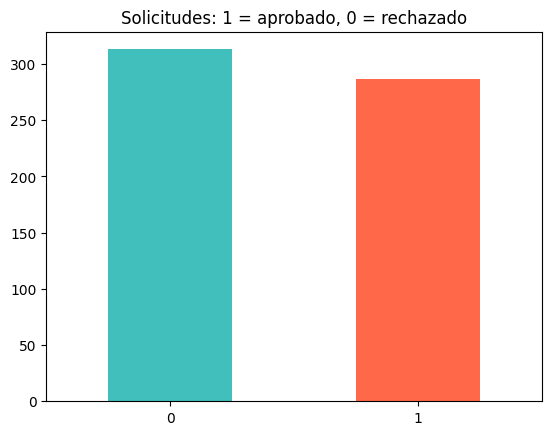

In [6]:
conteo = df['aprobado'].value_counts()
print(conteo)

ax = conteo.plot(kind='bar', color=['#41BFBC', '#FF6849'])
ax.set_title('Solicitudes: 1 = aprobado, 0 = rechazado')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.show()


**Observación:** 287 aprobados (48%) y 313 rechazados (52%): las clases están **balanceadas**.
Por eso usaremos `scoring='f1'`, que equilibra Precision y Recall (rango 0 a 1 → 1 = deseado).


## Bloque A2 · X, y y división train/test



**Librería:** `train_test_split`.

* `X` = las 6 variables predictoras · `y` = la columna `aprobado`.
* `stratify=y` mantiene el 48% de aprobados tanto en entrenamiento como en prueba.
* **`X_test` no se usa para elegir hiperparámetros.** Se reserva para la evaluación final (Bloque A5).


In [7]:
from sklearn.model_selection import train_test_split

X = df.drop('aprobado', axis=1)
y = df['aprobado']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} filas | % aprobados: {y_train.mean() * 100:.1f}%")
print(f"Prueba:        {X_test.shape[0]} filas | % aprobados: {y_test.mean() * 100:.1f}%")


Entrenamiento: 480 filas | % aprobados: 47.9%
Prueba:        120 filas | % aprobados: 47.5%


## Bloque A3 · Modelo base en un `Pipeline`



**Librerías:** `Pipeline`, `StandardScaler`, `SVC`, `classification_report`.

Primero entrenamos un SVM con sus **valores por defecto** (`C=1`, `kernel='rbf'`, `gamma='scale'`).
Será la **línea base** para comparar.

**¿Por qué un `Pipeline`?** El escalador aprende la media y la desviación de los datos. Dentro de
`GridSearchCV`, el `Pipeline` hace que el escalador se ajuste **solo con los folds de entrenamiento** de
cada iteración; así el fold de validación se trata como datos nuevos y no hay fuga de datos.


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report

pipe = Pipeline([
    ('escalar', StandardScaler()),   # paso 1
    ('modelo', SVC()),               # paso 2: valores por defecto
])
pipe.fit(X_train, y_train)
y_pred_base = pipe.predict(X_test)

print(classification_report(y_test, y_pred_base, target_names=['Rechazado', 'Aprobado']))


              precision    recall  f1-score   support

   Rechazado       0.84      0.90      0.87        63
    Aprobado       0.88      0.81      0.84        57

    accuracy                           0.86       120
   macro avg       0.86      0.86      0.86       120
weighted avg       0.86      0.86      0.86       120



## Bloque A4 · `param_grid` y `GridSearchCV`



**Librería:** `GridSearchCV`.

**Notación `paso__parámetro`:** como el SVM está dentro del `Pipeline` en el paso llamado `'modelo'`,
cada hiperparámetro se escribe con ese prefijo y **dos guiones bajos**: `'modelo__C'`, `'modelo__gamma'`,
`'modelo__kernel'`. Si escribes solo `'C'`, aparece el error `Invalid parameter 'C' for estimator Pipeline`.

**Escala logarítmica:** `C` y `gamma` actúan por órdenes de magnitud, por eso los valores saltan ×10.

**Costo:** 4 valores de C × 4 de gamma × 2 kernels = **32 combinaciones**. Con `cv=5` son
32 × 5 = 160 entrenamientos, más 1 final del mejor modelo con todo `X_train` (`refit=True`).


In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'modelo__C':      [0.1, 1, 10, 100],
    'modelo__gamma':  [0.001, 0.01, 0.1, 1],
    'modelo__kernel': ['rbf', 'linear'],
}
print("Combinaciones:", 4 * 4 * 2)

grid = GridSearchCV(pipe, param_grid, cv=5, scoring='f1', n_jobs=-1,verbose=1)
grid.fit(X_train, y_train)   # recibe datos SIN escalar: el Pipeline escala en cada fold

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Mejor F1 promedio en CV: {grid.best_score_:.3f}")


Combinaciones: 32
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Mejores hiperparámetros: {'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}
Mejor F1 promedio en CV: 0.895


**Atributos que existen solo después de `fit()`:**

* `best_params_`: la mejor combinación.
* `best_score_`: su F1 **promedio en validación cruzada** (sobre `X_train`). **No** es el rendimiento final.
* `best_estimator_`: el `Pipeline` ya reentrenado con todo `X_train` usando la mejor combinación.
* `cv_results_`: los resultados de las 32 combinaciones (Bloque A6).


## Bloque A5 · Evaluación en prueba: base vs. optimizado



`grid.predict()` usa automáticamente `best_estimator_`. Ahora sí usamos `X_test`, que no participó
en la búsqueda.


In [10]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, ConfusionMatrixDisplay

y_pred_opt = grid.predict(X_test)
print(classification_report(y_test, y_pred_opt, target_names=['Rechazado', 'Aprobado']))


              precision    recall  f1-score   support

   Rechazado       0.87      0.92      0.89        63
    Aprobado       0.91      0.84      0.87        57

    accuracy                           0.88       120
   macro avg       0.89      0.88      0.88       120
weighted avg       0.88      0.88      0.88       120



In [11]:
comparacion = pd.DataFrame({
    'Modelo': ['Base (por defecto)', 'GridSearchCV'],
    'Accuracy': [accuracy_score(y_test, y_pred_base), accuracy_score(y_test, y_pred_opt)],
    'Recall': [recall_score(y_test, y_pred_base), recall_score(y_test, y_pred_opt)],
    'F1': [f1_score(y_test, y_pred_base), f1_score(y_test, y_pred_opt)],
})
comparacion.round(3)


,Modelo,Accuracy,Recall,F1
0,Base (por defecto),0.858,0.807,0.844
1,GridSearchCV,0.883,0.842,0.873


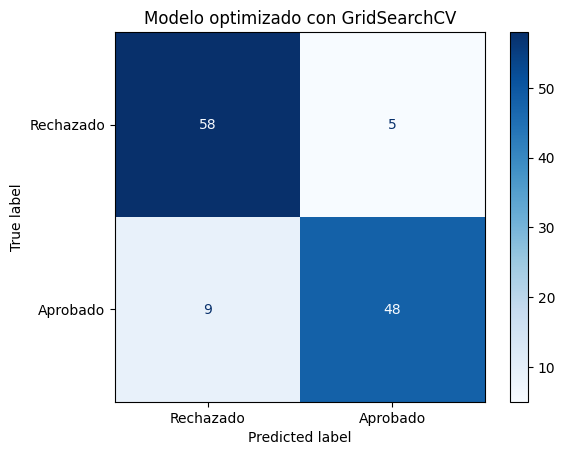

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_opt, display_labels=['Rechazado', 'Aprobado'], cmap='Blues')
plt.title('Modelo optimizado con GridSearchCV')
plt.show()


**Lectura** (métricas de la clase Aprobado; rango 0 a 1 → 1 = deseado):

* El modelo base obtiene F1 ≈ 0.84; el optimizado sube a F1 ≈ 0.87.
* El optimizado detecta 48 de los 57 aprobados reales; el base, 46. También mejora la Precision (0.88 → 0.91).
* La mejora está **respaldada por evidencia**: se compararon 32 configuraciones con validación cruzada.


## Bloque A6 · Explorar `cv_results_` con un mapa de calor



**Librería nueva:** `seaborn` (gráfico de mapa de calor).

`cv_results_` se convierte en un DataFrame con una fila por combinación. Las columnas más útiles:
`params` (la combinación), `mean_test_score` (F1 promedio en los 5 folds) y `rank_test_score` (1 = mejor).


In [13]:
pd.set_option('display.max_colwidth', None)   # mostrar el diccionario params completo

resultados = pd.DataFrame(grid.cv_results_)
resultados.sort_values('rank_test_score')[['params', 'mean_test_score', 'rank_test_score']].head(5)


,params,mean_test_score,rank_test_score
18,"{'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}",0.894956,1
12,"{'modelo__C': 1, 'modelo__gamma': 0.1, 'modelo__kernel': 'rbf'}",0.889936,2
26,"{'modelo__C': 100, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}",0.888972,3
10,"{'modelo__C': 1, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}",0.883126,4
17,"{'modelo__C': 10, 'modelo__gamma': 0.001, 'modelo__kernel': 'linear'}",0.882115,5


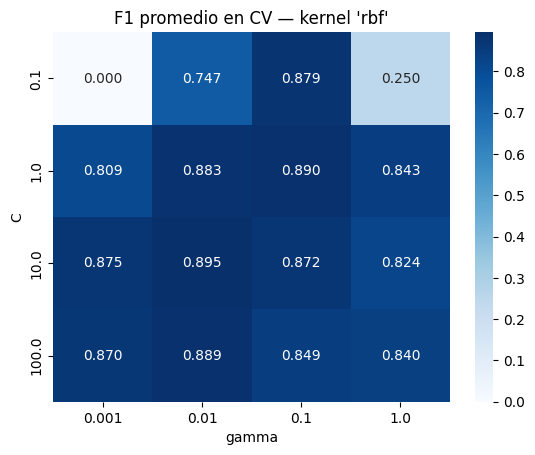

In [14]:
import seaborn as sns

rbf = resultados[resultados['param_modelo__kernel'] == 'rbf']
tabla = rbf.pivot_table(values='mean_test_score', index='param_modelo__C', columns='param_modelo__gamma')

sns.heatmap(tabla, annot=True, fmt='.3f', cmap='Blues')
plt.title("F1 promedio en CV — kernel 'rbf'")
plt.xlabel('gamma')
plt.ylabel('C')
plt.show()


**Lectura del mapa de calor:**

* `C = 0.1` con `gamma = 0.001` da **F1 = 0**: el modelo es tan simple que predice "rechazado" para todos → **underfitting**.
* Los valores extremos (C muy bajo, gamma muy alto) empeoran el F1.
* La mejor celda es `C = 10`, `gamma = 0.01` (F1 ≈ 0.895), en el **interior** del grid.
* **Buena práctica:** si el mejor valor hubiera quedado en el **borde** (por ejemplo `C = 100`), convendría
  ampliar el rango (probar `C = 1000`) antes de dar la búsqueda por terminada.


In [15]:
lineal = resultados[resultados['param_modelo__kernel'] == 'linear']
print(lineal.groupby('param_modelo__C')['mean_test_score'].mean().round(3))


param_modelo__C
0.1      0.880
1.0      0.873
10.0     0.882
100.0    0.882
Name: mean_test_score, dtype: float64


**Kernel lineal:** F1 ≈ 0.87–0.88 con cualquier valor de C, apenas por debajo del mejor RBF (≈ 0.895).
La frontera curva ayuda un poco, pero un modelo más simple queda muy cerca: **más complejo no siempre es mucho mejor**.


# Parte B — Práctica Autónoma: Detección de Diabetes



**Contexto:** se quiere identificar pacientes con riesgo de diabetes tipo 2 usando `diabetes_ecuador.csv`.

**¿Por qué `scoring='recall'`?** Un **falso negativo** (no detectar a un paciente con diabetes) es más
costoso que un falso positivo, que solo genera un examen adicional. Recall mide qué proporción de
los casos reales detecta el modelo (rango 0 a 1 → 1 = deseado).

En **tu propio notebook**, escribe el código que reemplace cada `# TODO` que ves en esta guía y responde
las preguntas en una celda de texto. Sigue la misma secuencia de la Parte A, con nombres terminados en `_b`.


## Bloque B1 · Datos y modelo base


In [37]:
# TODO 1: carga 'diabetes_ecuador.csv' en df_b y muestra cuántos casos hay de cada clase
df_b = pd.read_csv('diabetes_ecuador.csv')
print("Distribución de clases de diabetes:")
print(df_b['diabetes'].value_counts())

# TODO 2: construye X_b, y_b (objetivo: 'diabetes') y divide 80/20 con random_state=42 y stratify=y_b
X_b = df_b.drop('diabetes', axis=1)
y_b = df_b['diabetes']

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b
)

print(f"\nEntrenamiento: {X_train_b.shape[0]} filas | % diabetes: {y_train_b.mean() * 100:.1f}%")
print(f"Prueba:        {X_test_b.shape[0]} filas | % diabetes: {y_test_b.mean() * 100:.1f}%")

Distribución de clases de diabetes:
diabetes
0    341
1    259
Name: count, dtype: int64

Entrenamiento: 480 filas | % diabetes: 43.1%
Prueba:        120 filas | % diabetes: 43.3%


In [38]:
# TODO 3: crea pipe_b (mismo Pipeline del Bloque A3), entrénalo con X_train_b
#         y calcula el Recall del modelo base en X_test_b
from sklearn.metrics import recall_score

pipe_b = Pipeline([
    ('escalar', StandardScaler()),   # paso 1
    ('modelo', SVC()),               # paso 2: valores por defecto
])
pipe_b.fit(X_train_b, y_train_b)
y_pred_base_b = pipe_b.predict(X_test_b)
print("Recall base:", recall_score(y_test_b, y_pred_base_b))

Recall base: 0.7692307692307693


## Bloque B2 · `GridSearchCV` con `scoring='recall'`


In [39]:
# TODO 4: crea grid_b con el MISMO param_grid de la Parte A, cv=5, scoring='recall' y n_jobs=-1
#         Entrénalo con X_train_b y muestra best_params_ y best_score_

param_grid = {
    'modelo__C':      [0.1, 1, 10, 100],
    'modelo__gamma':  [0.001, 0.01, 0.1, 1],
    'modelo__kernel': ['rbf', 'linear'],
}
print("Combinaciones:", 4 * 4 * 2)

grid_b = GridSearchCV(pipe_b, param_grid, cv=5, scoring='recall', n_jobs=-1, verbose=1)
grid_b.fit(X_train_b, y_train_b)   # recibe datos SIN escalar: el Pipeline escala en cada fold

print("Mejores hiperparámetros:", grid_b.best_params_)
print(f"Mejor Recall promedio en CV: {grid_b.best_score_:.3f}")

Combinaciones: 32
Fitting 5 folds for each of 32 candidates, totalling 160 fits
Mejores hiperparámetros: {'modelo__C': 1, 'modelo__gamma': 0.001, 'modelo__kernel': 'linear'}
Mejor Recall promedio en CV: 0.836


In [40]:
# TODO 5: evalúa grid_b en X_test_b y arma una tabla base vs. optimizado
#         con Accuracy, Recall y F1 (mismo estilo que el Bloque A5)
from sklearn.metrics import accuracy_score, f1_score

y_pred_opt_b = grid_b.predict(X_test_b)
comparacion_b = pd.DataFrame({
    'Modelo': ['Base (por defecto)', 'GridSearchCV'],
    'Accuracy': [accuracy_score(y_test_b, y_pred_base_b), accuracy_score(y_test_b, y_pred_opt_b)],
    'Recall': [recall_score(y_test_b, y_pred_base_b), recall_score(y_test_b, y_pred_opt_b)],
    'F1': [f1_score(y_test_b, y_pred_base_b), f1_score(y_test_b, y_pred_opt_b)],
})
comparacion_b.round(3)

,Modelo,Accuracy,Recall,F1
0,Base (por defecto),0.817,0.769,0.784
1,GridSearchCV,0.867,0.885,0.852


Tabla de resultados del conjunto de prueba:

| Modelo | Hiperparametros | Accuracy | Recall | F1 |
| --- | --- | --- | --- | --- |
| Base | C=1, gamma=scale, rbf | 0.817 | 0.769 | 0.784 |
| GridSearchCV | C=1, kernel=linear | 0.867 | 0.885 | 0.852 |

**Preguntas:**

1. ¿Qué kernel eligió `GridSearchCV` para diabetes? ¿Es el mismo que eligió para crédito en la Parte A? ¿Qué dice eso sobre la forma de la frontera entre clases en cada dataset?


El kernel elegido por GridSearchCV para la deteccion de diabetes es el kernel lineal. Este resultado es diferente al del apartado A para el caso del credito, donde se selecciono un kernel rbf. Esto indica que las clases del dataset de diabetes son linealmente separables en el espacio de caracteristicas escalado, mientras que el de credito presenta una frontera de decision curva mas compleja.

2. ¿Cuántos pacientes con diabetes (de los que hay en `y_test_b`) detecta cada modelo? Usa el Recall para calcularlo.


En el conjunto de prueba hay un total de 52 pacientes que realmente tienen diabetes. El modelo base detecta a 40 de estos pacientes con su recall de 0.769. Por otra parte, el modelo optimizado logra detectar a 46 pacientes gracias a su recall de 0.885. Esto significa que el nuevo modelo ayuda a identificar a 6 personas enfermas mas que antes habrian sido ignoradas.

3. Si usaras `scoring='accuracy'`, ¿por qué podría elegirse un modelo distinto? ¿Cuál preferiría un médico y por qué?

Si se empleará accuracy, el algoritmo podria preferir un modelo diferente que clasifique mejor a las personas sanas aunque falle mas con las enfermas. Un medico siempre preferira el modelo optimizado con recall porque su prioridad absoluta es no dejar ningun enfermo sin tratamiento, disminuyendo los falsos negativos.

## Bloque B3 · Combinaciones repetidas: `param_grid` como lista de diccionarios



`gamma` solo afecta a los kernels `'rbf'` y `'poly'`; el kernel lineal **lo ignora**. Con el `param_grid`
de la Parte A, cada combinación lineal se entrena 4 veces (una por cada gamma) con el mismo resultado.

La solución es una **lista de diccionarios**: `GridSearchCV` explora cada diccionario por separado.

```
param_grid_lista = [
    {'modelo__kernel': ['rbf'],
     'modelo__C': [0.1, 1, 10, 100],
     'modelo__gamma': [0.001, 0.01, 0.1, 1]},   # 16 combinaciones
    {'modelo__kernel': ['linear'],
     'modelo__C': [0.1, 1, 10, 100]},           # 4 combinaciones
]
```


In [41]:
# TODO 6: muestra las 10 mejores filas de grid_b.cv_results_ (columnas params, mean_test_score,
#         rank_test_score), igual que en el Bloque A6. ¿Cuántas combinaciones comparten el rank 1?
resultados_b = pd.DataFrame(grid_b.cv_results_)
mejores_b = resultados_b.sort_values('rank_test_score')[['params', 'mean_test_score', 'rank_test_score']].head(10)
print("--- 10 mejores resultados de grid_b (Recall) ---")
print(mejores_b)

# TODO 7: define param_grid_lista (ver arriba), crea grid_b2 con cv=5 y scoring='recall',
#         entrénalo y muestra best_params_, best_score_ y len(grid_b2.cv_results_['params'])
param_grid_lista = [
    {
        'modelo__kernel': ['rbf'],
        'modelo__C': [0.1, 1, 10, 100],
        'modelo__gamma': [0.001, 0.01, 0.1, 1]
    },   # 16 combinaciones
    {
        'modelo__kernel': ['linear'],
        'modelo__C': [0.1, 1, 10, 100]
    }    # 4 combinaciones
]

grid_b2 = GridSearchCV(pipe_b, param_grid_lista, cv=5, scoring='recall', n_jobs=-1, verbose=1)
grid_b2.fit(X_train_b, y_train_b)

print("\n--- Resultados con param_grid optimizado (lista de diccionarios) ---")
print("Mejores hiperparámetros (grid_b2):", grid_b2.best_params_)
print(f"Mejor Recall promedio en CV (grid_b2): {grid_b2.best_score_:.3f}")
print("Total de combinaciones evaluadas por grid_b2:", len(grid_b2.cv_results_['params']))

--- 10 mejores resultados de grid_b (Recall) ---
                                                                    params  \
13      {'modelo__C': 1, 'modelo__gamma': 0.1, 'modelo__kernel': 'linear'}   
15        {'modelo__C': 1, 'modelo__gamma': 1, 'modelo__kernel': 'linear'}   
11     {'modelo__C': 1, 'modelo__gamma': 0.01, 'modelo__kernel': 'linear'}   
9     {'modelo__C': 1, 'modelo__gamma': 0.001, 'modelo__kernel': 'linear'}   
1   {'modelo__C': 0.1, 'modelo__gamma': 0.001, 'modelo__kernel': 'linear'}   
3    {'modelo__C': 0.1, 'modelo__gamma': 0.01, 'modelo__kernel': 'linear'}   
7       {'modelo__C': 0.1, 'modelo__gamma': 1, 'modelo__kernel': 'linear'}   
5     {'modelo__C': 0.1, 'modelo__gamma': 0.1, 'modelo__kernel': 'linear'}   
24     {'modelo__C': 100, 'modelo__gamma': 0.001, 'modelo__kernel': 'rbf'}   
21     {'modelo__C': 10, 'modelo__gamma': 0.1, 'modelo__kernel': 'linear'}   

    mean_test_score  rank_test_score  
13         0.835656                1  
15         0.8

**Preguntas:**

1. En `resultados_b`, ¿qué observas en `mean_test_score` de las filas con kernel lineal y el mismo C, pero distinto gamma? ¿Por qué ocurre?

Se observa que para el kernel lineal con un valor de C constante, la puntuacion de recall es exactamente la misma sin importar el valor de gamma. Esto sucede porque la definicion matematica del kernel lineal no hace uso del parametro gamma, haciendo que cualquier variacion en este ultimo sea ignorada por completo.

2. ¿Cuántas combinaciones evaluó `grid_b2`? ¿Cuántos entrenamientos se ahorraron con `cv=5`?

El optimizador grid_b2 evaluo exactamente 20 combinaciones distintas de hiperparametros. Al aplicar una validacion cruzada de 5 pliegues, esto resulto en un total de 100 entrenamientos. En comparacion con la busqueda inicial, se logro un ahorro de 12 combinaciones, lo que equivale a evitar 60 entrenamientos innecesarios.

3. ¿Cambió el mejor Recall en CV? ¿Por qué no debería cambiar?

El mejor recall obtenido mediante validacion cruzada no cambio y se mantuvo en 0.836. Este resultado es el esperado y no deberia cambiar porque la lista de diccionarios contiene exactamente las mismas combinaciones de parametros viables que la busqueda anterior, simplemente eliminando las pruebas repetidas.

# Bloque C — Entrenamiento Final, Exportación y Uso con Datos Nuevos



**Idea central:** el split 80/20 sirvió para **elegir** los hiperparámetros (con validación cruzada) y
para **medir** el modelo elegido (con `X_test`). Una vez decidido, el modelo final se entrena con el
**100% de los datos** de crédito: más datos ayudan al modelo que se va a usar en producción.


## C.1 · Reentrenar con el 100% de los datos



* **Modelo de evaluación (80%):** `grid`; sirvió para elegir y medir.
* **Pipeline final (100%):** se entrena con `X`, `y` completos usando los valores de `grid.best_params_`.


In [21]:
print(grid.best_params_)   # {'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}

pipeline_final = Pipeline([
    ('escalar', StandardScaler()),
    ('modelo', SVC(C=10, gamma=0.01, kernel='rbf')),   # valores de best_params_
])
pipeline_final.fit(X, y)   # X, y completos (600 filas), no X_train
print("pipeline_final entrenado con", len(X), "solicitudes.")


{'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}
pipeline_final entrenado con 600 solicitudes.


## C.2 · Exportar el pipeline con `joblib`



`joblib` guarda en un archivo `.pkl` el pipeline completo: la media y desviación del escalador y el SVM
con sus hiperparámetros, **juntos como un solo objeto**. Se exporta `pipeline_final`, no `grid`
(que además guarda los resultados de las 32 combinaciones).


In [22]:
import joblib

joblib.dump(pipeline_final, 'modelo_credito_svm.pkl')
print("Modelo exportado a modelo_credito_svm.pkl")


Modelo exportado a modelo_credito_svm.pkl


## C.3 · Usar el modelo con datos nuevos



Así se usaría el archivo **desde otro programa** (por ejemplo, una API): solo se necesita el `.pkl` y
tener instalados `pandas`, `scikit-learn` y `joblib`. El DataFrame lleva los datos **crudos** con las
mismas 6 columnas de `X`: `predict()` escala por dentro.


In [23]:
import joblib
import pandas as pd

modelo = joblib.load('modelo_credito_svm.pkl')

solicitudes_nuevas = pd.DataFrame({
    'edad': [35, 52, 28],
    'ingresos_mensuales': [1800, 1000, 1500],
    'deuda_total': [1200, 8000, 2500],
    'monto_solicitado': [6000, 9000, 5000],
    'historial_crediticio': [1, 1, 1],
    'empleo_estable': [1, 1, 1],
})

solicitudes_nuevas['prediccion'] = modelo.predict(solicitudes_nuevas)
solicitudes_nuevas['resultado'] = solicitudes_nuevas['prediccion'].map({1: 'APROBADO', 0: 'RECHAZADO'})
solicitudes_nuevas


,edad,ingresos_mensuales,deuda_total,monto_solicitado,historial_crediticio,empleo_estable,prediccion,resultado
0,35,1800,1200,6000,1,1,1,APROBADO
1,52,1000,8000,9000,1,1,0,RECHAZADO
2,28,1500,2500,5000,1,1,1,APROBADO


## Conclusiones



* Los hiperparámetros **no se aprenden** con `fit()`: se eligen comparando configuraciones con validación cruzada.
* El preprocesamiento va **dentro del `Pipeline`**; los nombres del `param_grid` llevan el prefijo del paso (`modelo__C`).
* `best_score_` es un promedio en CV; el rendimiento real se mide **una sola vez** en `X_test`.
* La métrica de `scoring` define qué significa "mejor": `f1` para crédito, `recall` para diabetes.
* El modelo final se reentrena con el 100% de los datos, se exporta con `joblib` y se usa con datos crudos.
